<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_heterogeneity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial heterogeneity: GWR and MGWR of poverty on night-time lights

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

Night-time lights are a common proxy for economic activity. Is their link with poverty the same everywhere in Bolivia? This notebook regresses **multidimensional poverty** (`sdg1_2_mpi`, 2012, 0–1; **higher = poorer**) on **log night-time lights per capita** (`ln_t400NTLpc`, 2012) across the 339 municipalities and lets the relationship vary over space.

Outline:

1. **Load** the data with `geo4bolivia`
2. **Global regression** (OLS): one slope for the whole country
3. **Geographically weighted regression** (GWR): one slope per municipality, a single bandwidth
4. **Multiscale GWR** (MGWR): a separate bandwidth for the intercept and the slope
5. **Comparison** of the three models

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "mgwr"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import geo4bolivia as geo
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
from mgwr.diagnostics import get_AICc
from spglm.glm import GLM

import warnings
warnings.filterwarnings("ignore")

## 1. Load the data

Poverty comes from the SDG Atlas at its reference year (2012) and lights from the `ntl` dataset in the same year. All 339 municipalities have both values. The GWR kernels need one point per municipality: we use the centroids in the observatory's equal-area projection, in kilometres.

In [3]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", years=2012, geometry=True)
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=2012)

units = geo.units("municipality")
departments = geo.units("department").set_index("geo_id")["name"]

gdf = (mpi.merge(ntl[["geo_id", "ln_t400NTLpc"]], on="geo_id")
          .merge(units[["geo_id", "department_id"]], on="geo_id"))
gdf["department"] = gdf["department_id"].map(departments)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])

MPI, NTL = "sdg1_2_mpi", "ln_t400NTLpc"
print(gdf.shape, "| missing values:", int(gdf[[MPI, NTL]].isna().sum().sum()))
gdf[["geo_id", "name", "department", MPI, NTL]].head()

(339, 8) | missing values: 0


,geo_id,name,department,sdg1_2_mpi,ln_t400NTLpc
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,11.048312
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,12.329279
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,12.815315
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,12.018971
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,14.603350


In [4]:
y = gdf[[MPI]].values                       # (339, 1)
X = gdf[[NTL]].values                       # (339, 1); mgwr adds the intercept
centroids = gdf.geometry.centroid
coords = np.column_stack([centroids.x, centroids.y]) / 1000   # km

# department outlines for the maps
dep_lines = geo.boundaries("department").to_crs(gdf.crs).boundary
print(f"y {y.shape}, X {X.shape}, coords {coords.shape}")

y (339, 1), X (339, 1), coords (339, 2)


## 2. Global regression

Ordinary least squares fits one intercept and one slope for the whole country.

In [5]:
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(ols.summary(xname=["const", NTL], yname=MPI).tables[1])
print(f"R2 = {ols.rsquared:.3f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.5877      0.035     16.622      0.000       0.518       0.657
ln_t400NTLpc    -0.0314      0.003    -11.654      0.000      -0.037      -0.026
R2 = 0.287


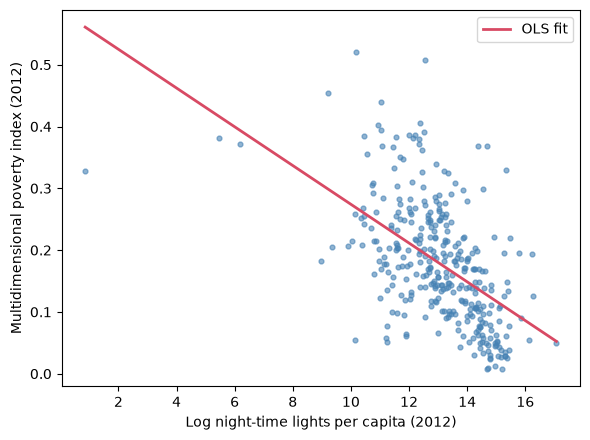

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(gdf[NTL], gdf[MPI], s=12, alpha=0.6, color="steelblue")
xs = np.linspace(gdf[NTL].min(), gdf[NTL].max(), 100)
ax.plot(xs, ols.params[0] + ols.params[1] * xs, color="#d84a64", lw=2, label="OLS fit")
ax.set_xlabel("Log night-time lights per capita (2012)")
ax.set_ylabel("Multidimensional poverty index (2012)")
ax.legend()
plt.tight_layout()
plt.show()

Across the country, brighter municipalities are less poor. The OLS slope is −0.031: one more log point of lights per capita (about 2.7 times more light per person) goes with an MPI 0.031 lower, about a third of the cross-municipal standard deviation of poverty (0.098). Lights alone explain 29% of the variation in poverty (R² = 0.287). A few very dark outliers sit on the left, and the cloud of points is wide, which suggests that one slope may not fit all regions.

## 3. Geographically weighted regression (GWR)

GWR estimates a separate regression at each municipality, weighting the other municipalities by distance with a bisquare kernel. The **bandwidth** (the number of nearest neighbours in each local regression) is chosen by minimising AICc: a small bandwidth means the relationship changes quickly over space.

In [7]:
gwr_selector = Sel_BW(coords, y, X)
gwr_bw = gwr_selector.search(criterion="AICc")
print("GWR bandwidth (nearest neighbours) =", gwr_bw)

GWR bandwidth (nearest neighbours) = 46.0


In [8]:
gwr_results = GWR(coords, y, X, gwr_bw, name_x=[NTL]).fit()
gwr_results.summary()

Model type                                                         Gaussian
Number of observations:                                                 339
Number of covariates:                                                     2

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                              2.305
Log-likelihood:                                                     364.976
AIC:                                                               -725.952
AICc:                                                              -723.880
BIC:                                                              -1961.058
R2:                                                                   0.287
Adj. R2:                                                              0.285

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [9]:
print("Bandwidth confidence interval:", gwr_results.get_bws_intervals(gwr_selector))
print(f"R2 = {gwr_results.R2:.3f}, adj. R2 = {gwr_results.adj_R2:.3f}, AICc = {gwr_results.aicc:.1f}")

Bandwidth confidence interval: (np.float64(46.0), np.float64(50.0))
R2 = 0.624, adj. R2 = 0.577, AICc = -859.4


In [10]:
gdf["gwr_intercept"] = gwr_results.params[:, 0]
gdf["gwr_slope"] = gwr_results.params[:, 1]
gdf["gwr_R2"] = gwr_results.localR2[:, 0]

gwr_sig = gwr_results.filter_tvals(alpha=0.05)    # 0 where |t| < 1.96
gwr_sig_c = gwr_results.filter_tvals()            # 0 where not significant after correction for multiple tests
print("Significant slopes (5%):", int((gwr_sig[:, 1] != 0).sum()),
      "| after correction:", int((gwr_sig_c[:, 1] != 0).sum()), "of", len(gdf))
print("Negative slopes:", int((gdf["gwr_slope"] < 0).sum()))
gdf[["gwr_intercept", "gwr_slope", "gwr_R2"]].describe().round(4)

Significant slopes (5%): 293 | after correction: 194 of 339
Negative slopes: 339


,gwr_intercept,gwr_slope,gwr_R2
count,339.0000,339.0000,339.0000
mean,0.6730,-0.0376,0.4956
std,0.2896,0.0207,0.1884
min,0.2295,-0.0946,0.0709
25%,0.4389,-0.0548,0.3415
50%,0.5659,-0.0303,0.5056
75%,0.9101,-0.0197,0.6675
max,1.4863,-0.0040,0.8239


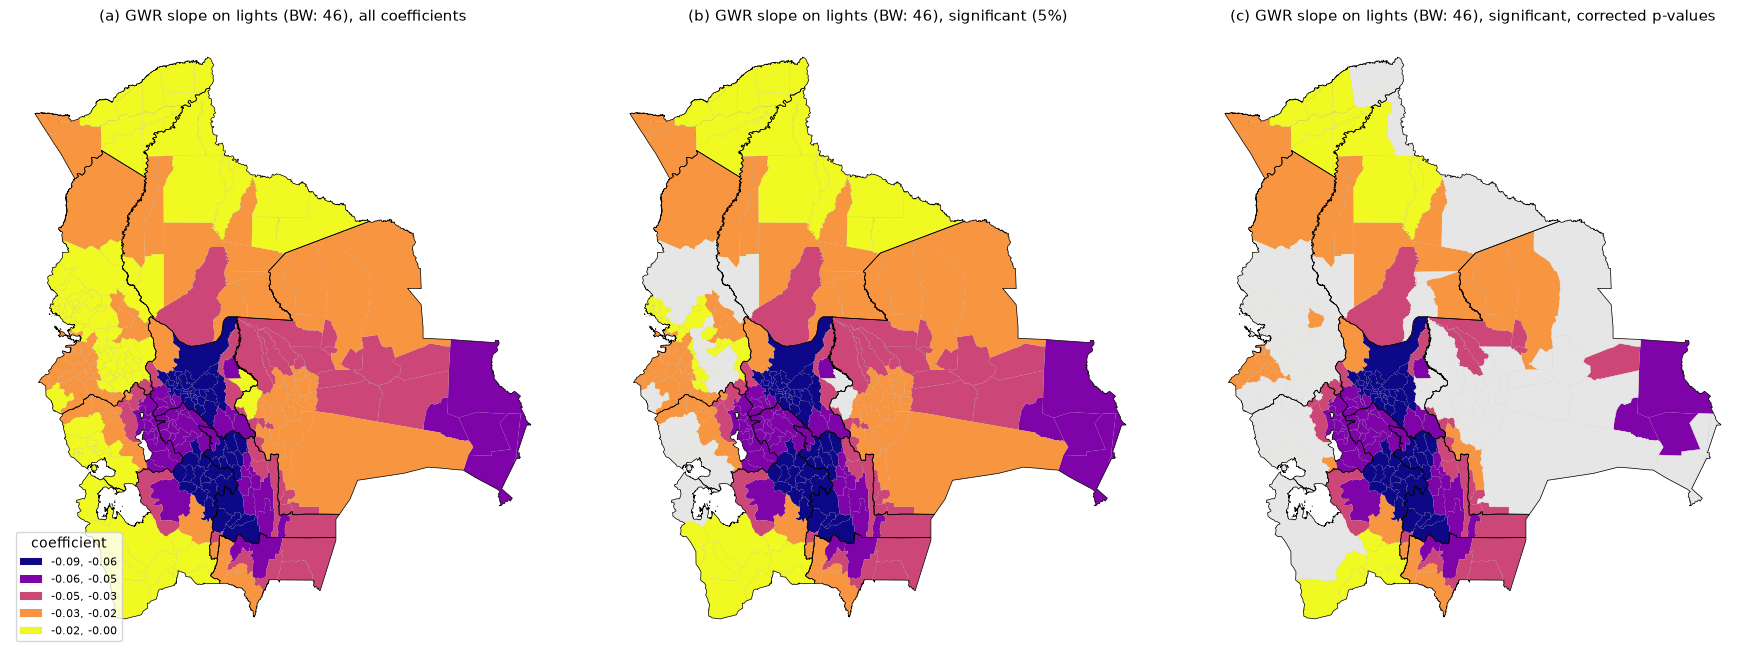

In [11]:
def plot_coefficient(column, sig, sig_c, title, bw):
    """Three maps: all local coefficients, significant ones (5%), significant after correction.
    Non-significant municipalities are shaded light grey."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
    kw = dict(column=column, cmap="plasma", scheme="FisherJenks", k=5, linewidth=0.05, edgecolor="grey")
    panels = [("all coefficients", None),
              ("significant (5%)", sig),
              ("significant, corrected p-values", sig_c)]
    for i, (ax, (label, mask)) in enumerate(zip(axes, panels)):
        gdf.plot(ax=ax, legend=(i == 0),
                 legend_kwds={"loc": "lower left", "fontsize": 8, "title": "coefficient"}, **kw)
        if mask is not None:
            gdf[mask == 0].plot(ax=ax, color="#e6e6e6", edgecolor="#e6e6e6", linewidth=0.3)
        dep_lines.plot(ax=ax, color="black", linewidth=0.5)
        ax.set_title(f"({'abc'[i]}) {title} (BW: {bw}), {label}", fontsize=11)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

plot_coefficient("gwr_slope", gwr_sig[:, 1], gwr_sig_c[:, 1], "GWR slope on lights", int(gwr_bw))

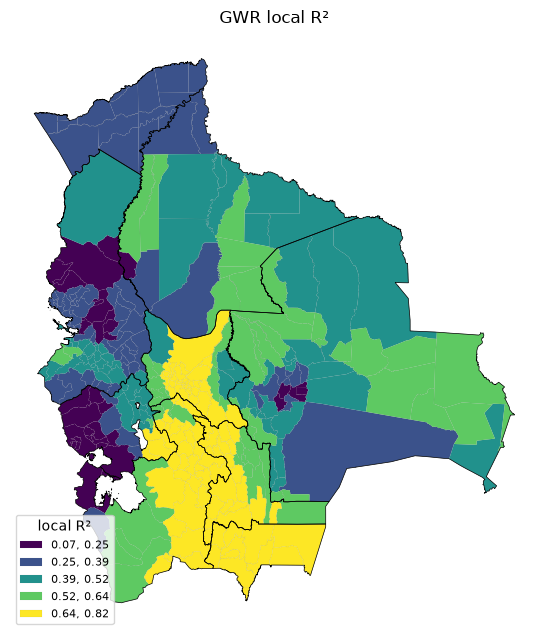

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
gdf.plot(column="gwr_R2", cmap="viridis", scheme="FisherJenks", k=5, linewidth=0.05, edgecolor="grey",
         legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": "local R²"}, ax=ax)
dep_lines.plot(ax=ax, color="black", linewidth=0.5)
ax.set_title("GWR local R²")
ax.set_axis_off()
plt.tight_layout()
plt.show()

The AICc-optimal bandwidth is **46 nearest neighbours** (95% interval 46–50), about 14% of the municipalities, so each local regression is genuinely local. Letting the relationship vary raises R² from 0.287 to 0.624 (adjusted 0.577) and lowers AICc from −723.9 to −859.5, with about 38 effective parameters.

- **The sign never changes**: all 339 local slopes are negative, from −0.095 to −0.004. More light goes with less poverty everywhere; what varies is the strength.
- The slope is **steepest in the Andean valleys** of Cochabamba, Chuquisaca and eastern Potosí (department averages −0.065, −0.059 and −0.049), and also steep along the eastern border of Santa Cruz.
- It is **weakest in the Amazonian north** (Pando, northern Beni), on the **La Paz altiplano** and in southwestern Potosí (around −0.02). In much of La Paz and Oruro the local slope is not significant, even at 5% without correction.
- 293 local slopes are significant at 5%, and 194 after correcting for the multiple tests that GWR implies (adjusted critical t = 3.03).
- The local R² follows the same geography: lights explain 65–82% of poverty in the valleys of Cochabamba, Chuquisaca and Potosí and in the Chaco of Tarija and southern Santa Cruz, but less than 25% in parts of the La Paz and Oruro highlands.

## 4. Multiscale GWR (MGWR)

GWR forces the intercept and the slope to vary at the same spatial scale. MGWR selects **one bandwidth per coefficient**: a bandwidth close to the number of municipalities (339) means the coefficient is essentially global, a small one means it is local. As in the original DS4Bolivia notebook, the variables are standardised (mean 0, standard deviation 1), so the slope is in standard deviations of MPI per standard deviation of lights.

In [13]:
Zy = (y - y.mean(axis=0)) / y.std(axis=0)
ZX = (X - X.mean(axis=0)) / X.std(axis=0)

mgwr_selector = Sel_BW(coords, Zy, ZX, multi=True)
mgwr_bw = mgwr_selector.search(criterion="AICc")
print("MGWR bandwidths (intercept, lights) =", mgwr_bw)

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

MGWR bandwidths (intercept, lights) = [44. 65.]


In [14]:
mgwr_results = MGWR(coords, Zy, ZX, mgwr_selector, name_x=[NTL]).fit()
mgwr_results.summary()

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Model type                                                         Gaussian
Number of observations:                                                 339
Number of covariates:                                                     2

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            241.620
Log-likelihood:                                                    -423.621
AIC:                                                                851.243
AICc:                                                               853.315
BIC:                                                              -1721.742
R2:                                                                   0.287
Adj. R2:                                                              0.285

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [15]:
print("Bandwidth confidence intervals:", mgwr_results.get_bws_intervals(mgwr_selector))
print(f"R2 = {mgwr_results.R2:.3f}, adj. R2 = {mgwr_results.adj_R2:.3f}, AICc = {mgwr_results.aicc:.1f}")

Bandwidth confidence intervals: [(np.float64(44.0), np.float64(48.0)), (np.float64(64.0), np.float64(85.0))]
R2 = 0.633, adj. R2 = 0.592, AICc = 701.4


In [16]:
gdf["mgwr_intercept"] = mgwr_results.params[:, 0]
gdf["mgwr_slope"] = mgwr_results.params[:, 1]

mgwr_sig = mgwr_results.filter_tvals(alpha=0.05)
mgwr_sig_c = mgwr_results.filter_tvals()
print("Significant slopes (5%):", int((mgwr_sig[:, 1] != 0).sum()),
      "| after correction:", int((mgwr_sig_c[:, 1] != 0).sum()), "of", len(gdf))
print("Negative slopes:", int((gdf["mgwr_slope"] < 0).sum()))
gdf[["mgwr_intercept", "mgwr_slope"]].describe().round(4)

Significant slopes (5%): 331 | after correction: 260 of 339
Negative slopes: 339


,mgwr_intercept,mgwr_slope
count,339.0000,339.0000
mean,0.0214,-0.6174
std,0.3853,0.3150
min,-0.7835,-1.2290
25%,-0.3005,-0.9118
50%,0.0283,-0.4672
75%,0.2786,-0.3561
max,0.9502,-0.2011


In [17]:
# average local estimates by department
(gdf.groupby("department")[["gwr_slope", "gwr_R2", "mgwr_slope"]]
    .mean().sort_values("mgwr_slope").round(3))

,gwr_slope,gwr_R2,mgwr_slope
department,,,
Cochabamba,-0.065,0.652,-1.070
Chuquisaca,-0.059,0.698,-0.958
Potosí,-0.049,0.666,-0.820
Oruro,-0.031,0.317,-0.574
Tarija,-0.037,0.755,-0.560
Santa Cruz,-0.036,0.465,-0.500
Pando,-0.020,0.284,-0.392
Beni,-0.021,0.459,-0.390
La Paz,-0.021,0.369,-0.355


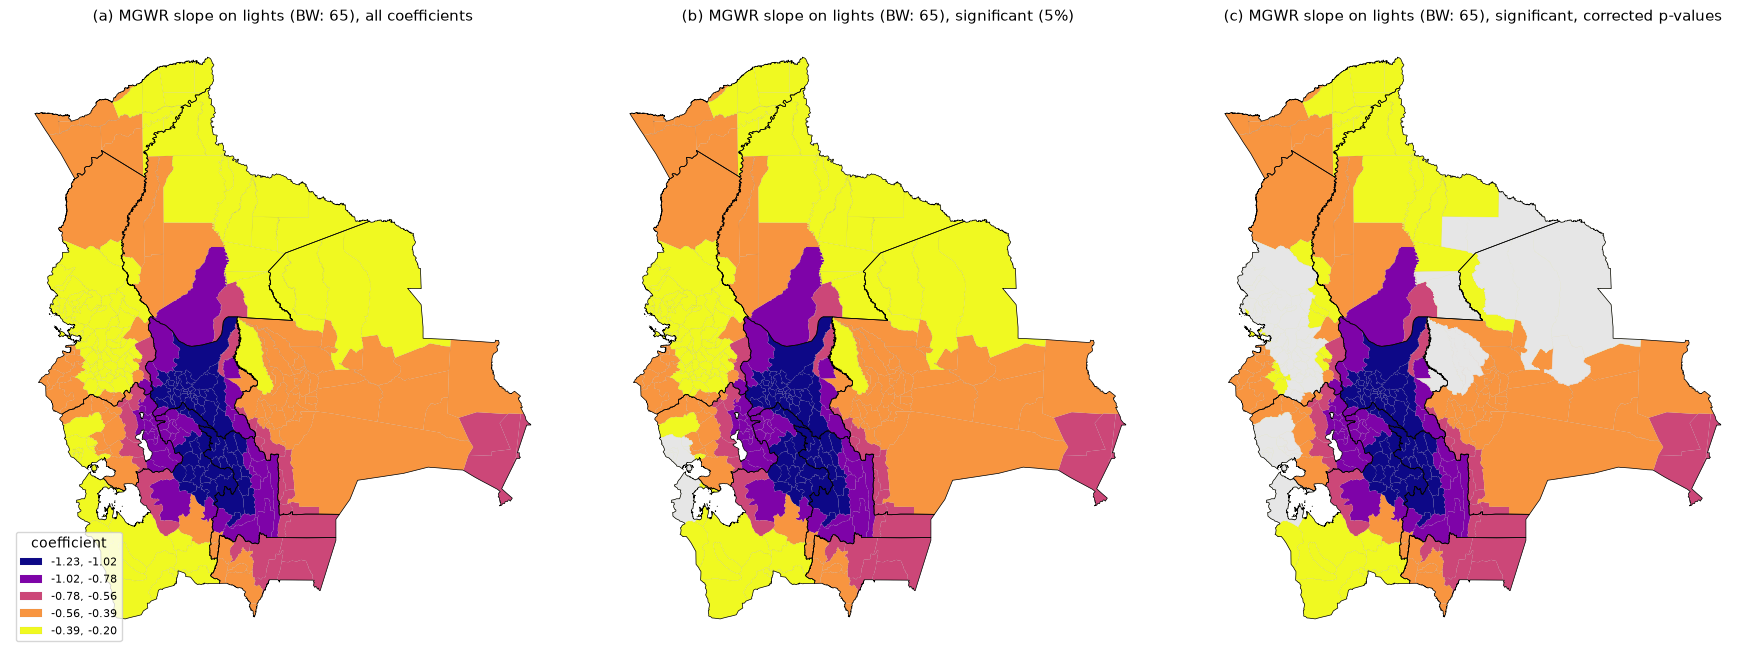

In [18]:
plot_coefficient("mgwr_slope", mgwr_sig[:, 1], mgwr_sig_c[:, 1],
                 "MGWR slope on lights", int(mgwr_bw[1]))

MGWR selects a bandwidth of **44 neighbours for the intercept** (interval 44–48) and **66 for the slope on lights** (interval 64–85). Both are far below 339, so both the baseline level of poverty and its link with lights vary locally; the slope varies over a somewhat larger scale than the intercept, a difference GWR cannot detect because it uses one bandwidth for both.

In standardised units, every local slope is again negative, from −1.23 to −0.21 standard deviations of MPI per standard deviation of lights (OLS: −0.54). 333 slopes are significant at 5% and 262 after correction. The map repeats the GWR pattern, more smoothly: the strongest association in Cochabamba (average −1.07), Chuquisaca (−0.96) and Potosí (−0.82), and the weakest in La Paz (−0.36), Beni and Pando (both −0.39).

## 5. Comparison

To compare like with like, the three models are evaluated on the standardised variables (GWR's bandwidth and fit do not change with standardisation; only the scale of AICc does).

In [19]:
ols_z = GLM(Zy, sm.add_constant(ZX), constant=False).fit()
gwr_z = GWR(coords, Zy, ZX, gwr_bw).fit()

comparison = pd.DataFrame({
    "OLS":  {"bandwidth (intercept, lights)": "global", "R2": 1 - ols_z.deviance / ols_z.null_deviance,
             "adj. R2": ols.rsquared_adj, "AICc": get_AICc(ols_z), "effective parameters": 2.0},
    "GWR":  {"bandwidth (intercept, lights)": f"{int(gwr_bw)}, {int(gwr_bw)}", "R2": gwr_z.R2,
             "adj. R2": gwr_z.adj_R2, "AICc": gwr_z.aicc, "effective parameters": gwr_z.ENP},
    "MGWR": {"bandwidth (intercept, lights)": f"{int(mgwr_bw[0])}, {int(mgwr_bw[1])}", "R2": mgwr_results.R2,
             "adj. R2": mgwr_results.adj_R2, "AICc": mgwr_results.aicc, "effective parameters": mgwr_results.ENP},
}).T
comparison.round(3)

,"bandwidth (intercept, lights)",R2,adj. R2,AICc,effective parameters
OLS,global,0.287258,0.285143,853.314574,2.0
GWR,"46, 46",0.624155,0.577089,717.755032,37.616579
MGWR,"44, 65",0.633108,0.591544,701.43172,34.394331


- Both local models fit far better than OLS: R² rises from 0.29 to 0.62 (GWR) and 0.63 (MGWR). **MGWR is preferred**: it has the lowest AICc (701.5, against 717.7 for GWR and 853.3 for OLS) with fewer effective parameters than GWR (34 against 38).
- **The relationship is spatially heterogeneous but has one sign.** Lights are associated with lower poverty in every municipality. In MGWR the association is about three times stronger in Cochabamba than in La Paz (department averages −1.07 and −0.36), and locally it ranges six-fold (−1.23 to −0.21).
- As a proxy for poverty, night-time lights are therefore most informative in the Andean valleys and least informative on the altiplano and in the Amazon. The companion notebook `embeddings_mpi_ml` tests whether satellite embeddings do better.
- These are associations from a one-variable model, not causal effects. Local coefficients can also absorb omitted regional factors (altitude, remoteness, market access).

Related notebooks: `esda_dependence` (spatial autocorrelation of poverty and lights) and `esda_inequality` (Theil and Gini decompositions).